# 03 · Modelado

**Universidad de Especialidades Espíritu Santo (UEES)** · Maestría en Inteligencia Artificial
**Proyecto Integrador en Inteligencia Artificial (MIAR0545)** · Proyecto final
**Autor:** Jairo Wladimir Jhayya Perlaza · **Docente:** Gladys María Villegas Rugel · **Fecha:** octubre de 2026

**Proyecto:** Análisis comparativo de modelos de aprendizaje automático y arquitecturas Transformer para la clasificación
de tráfico de red cifrado sobre el dataset CESNET-TLS-Year22.


Este notebook presenta los cuatro modelos comparados en el proyecto, cómo se configuraron y cómo se comparan entre sí
y con un clasificador al azar. Lee los resultados que guardaron los scripts de entrenamiento (`scripts/03` y
`scripts/05`) y la comparación (`scripts/04`), así que no vuelve a entrenar nada.

## Configuración

Se cargan las librerías y se ubica la raíz del proyecto subiendo carpetas hasta encontrar `configs/`, así el notebook
funciona sin importar desde dónde se abra. También se definen dos funciones pequeñas para leer resultados y mostrar
figuras.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

# La raíz del proyecto es la primera carpeta, subiendo desde aquí, que contiene configs/
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").exists())
RES = RAIZ / "results"
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 60)


def leer_json(ruta):
    """Lee un archivo JSON de resultados."""
    return json.loads(Path(ruta).read_text(encoding="utf-8"))


def figura(ruta, ancho=900):
    """Muestra una figura guardada por los scripts del proyecto."""
    display(Image(filename=str(ruta), width=ancho))


print("Raíz del proyecto:", RAIZ.name, "· resultados disponibles:", RES.exists())

Raíz del proyecto: pf · resultados disponibles: True


## 1. Los cuatro modelos

El proyecto compara dos familias. Los modelos de árboles, Random Forest y XGBoost, usan las 60 variables tabulares.
Las redes neuronales, una CNN 1D y un Transformer ligero, usan la secuencia de los primeros 30 paquetes. La celda
muestra la configuración vigente de cada uno, tal como está en `configs/experiment.yaml`.

In [2]:
cfg = yaml.safe_load((RAIZ / "configs" / "experiment.yaml").read_text(encoding="utf-8"))
filas = []
for nombre in ["random_forest", "xgboost", "cnn1d", "transformer"]:
    parametros = cfg["modelos"][nombre]
    filas.append({"Modelo": nombre, "Configuración": ", ".join(f"{k}={v}" for k, v in parametros.items())})
pd.DataFrame(filas)

,Modelo,Configuración
0,random_forest,"n_estimators=100, max_depth=20, min_samples_leaf=1, max_..."
1,xgboost,"n_estimators=1000, max_depth=8, learning_rate=0.1, tree_..."
2,cnn1d,"canales=[64, 128], kernel=3, dropout=0.2, epocas=50, lr=..."
3,transformer,"d_model=64, cabezas=4, capas=2, ff=128, dropout=0.1, epo..."


## 2. El punto de partida: un clasificador al azar

Antes de comparar modelos hay que saber cuánto vale no saber nada. Un clasificador que adivina respetando la proporción
de cada categoría obtiene un F1 macro cercano a 1/23. La tabla, de la semana 5, lo compara con XGBoost en 100 000 flujos
de octubre.

In [3]:
pd.read_csv(RES / "semana5" / "parte0" / "tabla_octubre.csv").drop(columns=["peor_categoria"])

,modelo,accuracy,f1_macro,recall_macro,precision_macro,f1_peor_categoria,auc_ovr,auc_pr
0,dummy,0.0652,0.0436,0.0437,0.0437,0.000,0.5001,0.0435
1,xgboost_v2 (producción),0.8982,0.9009,0.9008,0.9020,0.822,0.9962,0.9560


## 3. Comparación de los cuatro modelos

La tabla resume la versión vigente de cada modelo en la prueba de octubre: su F1 macro, el F1 sin las secuencias
repetidas, su comportamiento en noviembre y diciembre, el tiempo que tarda en clasificar un flujo y su tamaño.

In [4]:
tabla = pd.read_csv(RES / "comparativa" / "tabla_comparativa.csv", index_col=0)
tabla

,f1_macro,f1_macro_sin_repetidos,f1_ponderado,exactitud,f1_macro_2022-11,f1_macro_2022-12,latencia_ms,tamano_MB,entrenamiento_min
modelo,,,,,,,,,
random_forest,0.8602,0.8329,0.8681,0.8673,0.8279,0.8172,0.0340,173.00,0.4
xgboost,0.9032,0.8853,0.9006,0.9004,0.8706,0.8556,0.1486,58.90,89.6
cnn1d,0.8010,0.7893,0.8265,0.8260,0.7628,0.7482,0.0150,0.12,46.8
transformer,0.8332,0.8355,0.8653,0.8650,0.7904,0.7734,0.0443,0.30,188.4


XGBoost es el más preciso, con 0,903 de F1 macro, y el que mejor resiste la deriva. Random Forest le sigue con 0,860.
Las redes son más livianas, pero menos precisas. El Transformer tiene un detalle interesante: su F1 sin secuencias
repetidas es igual o mayor que con ellas, señal de que memoriza menos. La figura muestra el equilibrio entre precisión
y tiempo de respuesta.

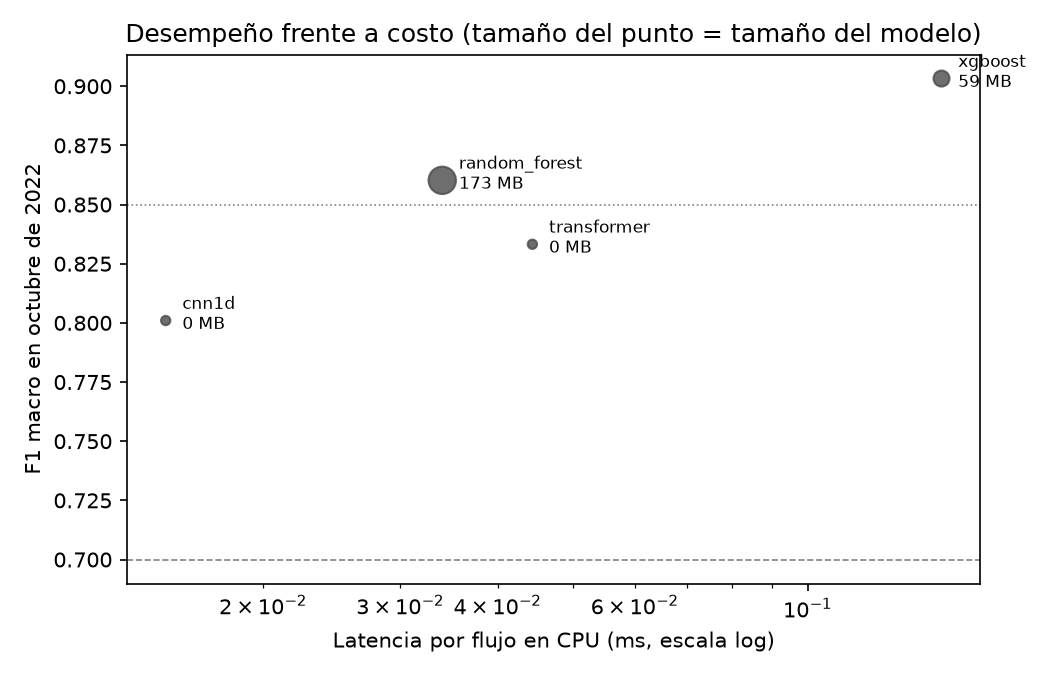

In [5]:
figura(RES / "comparativa" / "f1_vs_latencia.png", ancho=700)

## 4. ¿Las diferencias son reales?

Dos modelos con F1 parecidos pueden no diferir de verdad. La prueba de McNemar compara, flujo por flujo, los aciertos
de cada par de modelos, y la corrección de Holm ajusta los valores p porque se hacen seis comparaciones a la vez.

In [6]:
pd.read_csv(RES / "comparativa" / "mcnemar.csv")[["modelo_A", "modelo_B", "mejor", "p_holm", "significativo"]]

,modelo_A,modelo_B,mejor,p_holm,significativo
0,random_forest,xgboost,xgboost,0.0000e+00,True
1,random_forest,cnn1d,random_forest,0.0000e+00,True
2,random_forest,transformer,random_forest,3.4596e-09,True
3,xgboost,cnn1d,xgboost,0.0000e+00,True
4,xgboost,transformer,xgboost,0.0000e+00,True
5,cnn1d,transformer,transformer,0.0000e+00,True


Las seis diferencias son significativas. El orden queda establecido con respaldo estadístico: XGBoost, Random Forest,
Transformer y CNN 1D.

## 5. De la versión 1 a la versión 2

Los modelos se reentrenaron después del diagnóstico de la semana 3, que mostró que estaban en subajuste. Cada versión 2
solo reemplazó a la versión 1 si mejoraba el F1 de validación, sin mirar la prueba.

In [7]:
versiones = pd.read_csv(RES / "comparativa" / "versiones.csv")
versiones[["modelo", "f1_validacion_v1", "f1_validacion_v2", "decision", "f1_prueba_v1", "f1_prueba_v2", "mejora_prueba_puntos"]]

,modelo,f1_validacion_v1,f1_validacion_v2,decision,f1_prueba_v1,f1_prueba_v2,mejora_prueba_puntos
0,random_forest,0.8132,0.8759,v2,0.8041,0.8602,5.6154
1,xgboost,0.9026,0.9159,v2,0.8861,0.9032,1.7113
2,cnn1d,0.7107,0.8136,v2,0.7004,0.8010,10.0590
3,transformer,0.7607,0.8461,v2,0.7474,0.8332,8.5791


Los cuatro modelos mejoraron y adoptaron la versión 2. Las redes ganaron entre 8 y 10 puntos, porque eran las más
afectadas por el subajuste.

## 6. XGBoost en detalle

El promedio esconde diferencias entre categorías. La tabla muestra las categorías donde XGBoost acierta menos y más.

In [8]:
por_clase = pd.read_csv(RES / "modelos" / "xgboost" / "reporte_por_clase.csv", index_col=0)
por_clase = por_clase.drop(index=[i for i in ("accuracy", "macro avg", "weighted avg") if i in por_clase.index])
por_clase = por_clase.sort_values("f1-score")
pd.concat([por_clase.head(4), por_clase.tail(3)])

,precision,recall,f1-score,support
Media,0.8313,0.8279,0.8296,70156.0
Search,0.8325,0.8768,0.8541,32843.0
Advertising,0.8629,0.8648,0.8639,86806.0
Information systems,0.8270,0.9058,0.8646,10735.0
Software updates,0.9620,0.9627,0.9623,32225.0
Analytics & Telemetry,0.9851,0.9628,0.9738,67381.0
Notifications,0.9839,0.9875,0.9857,18287.0


Media, Search y Advertising son las más difíciles, porque comparten infraestructura con otros servicios. La matriz de
confusión muestra con quién se confunden.

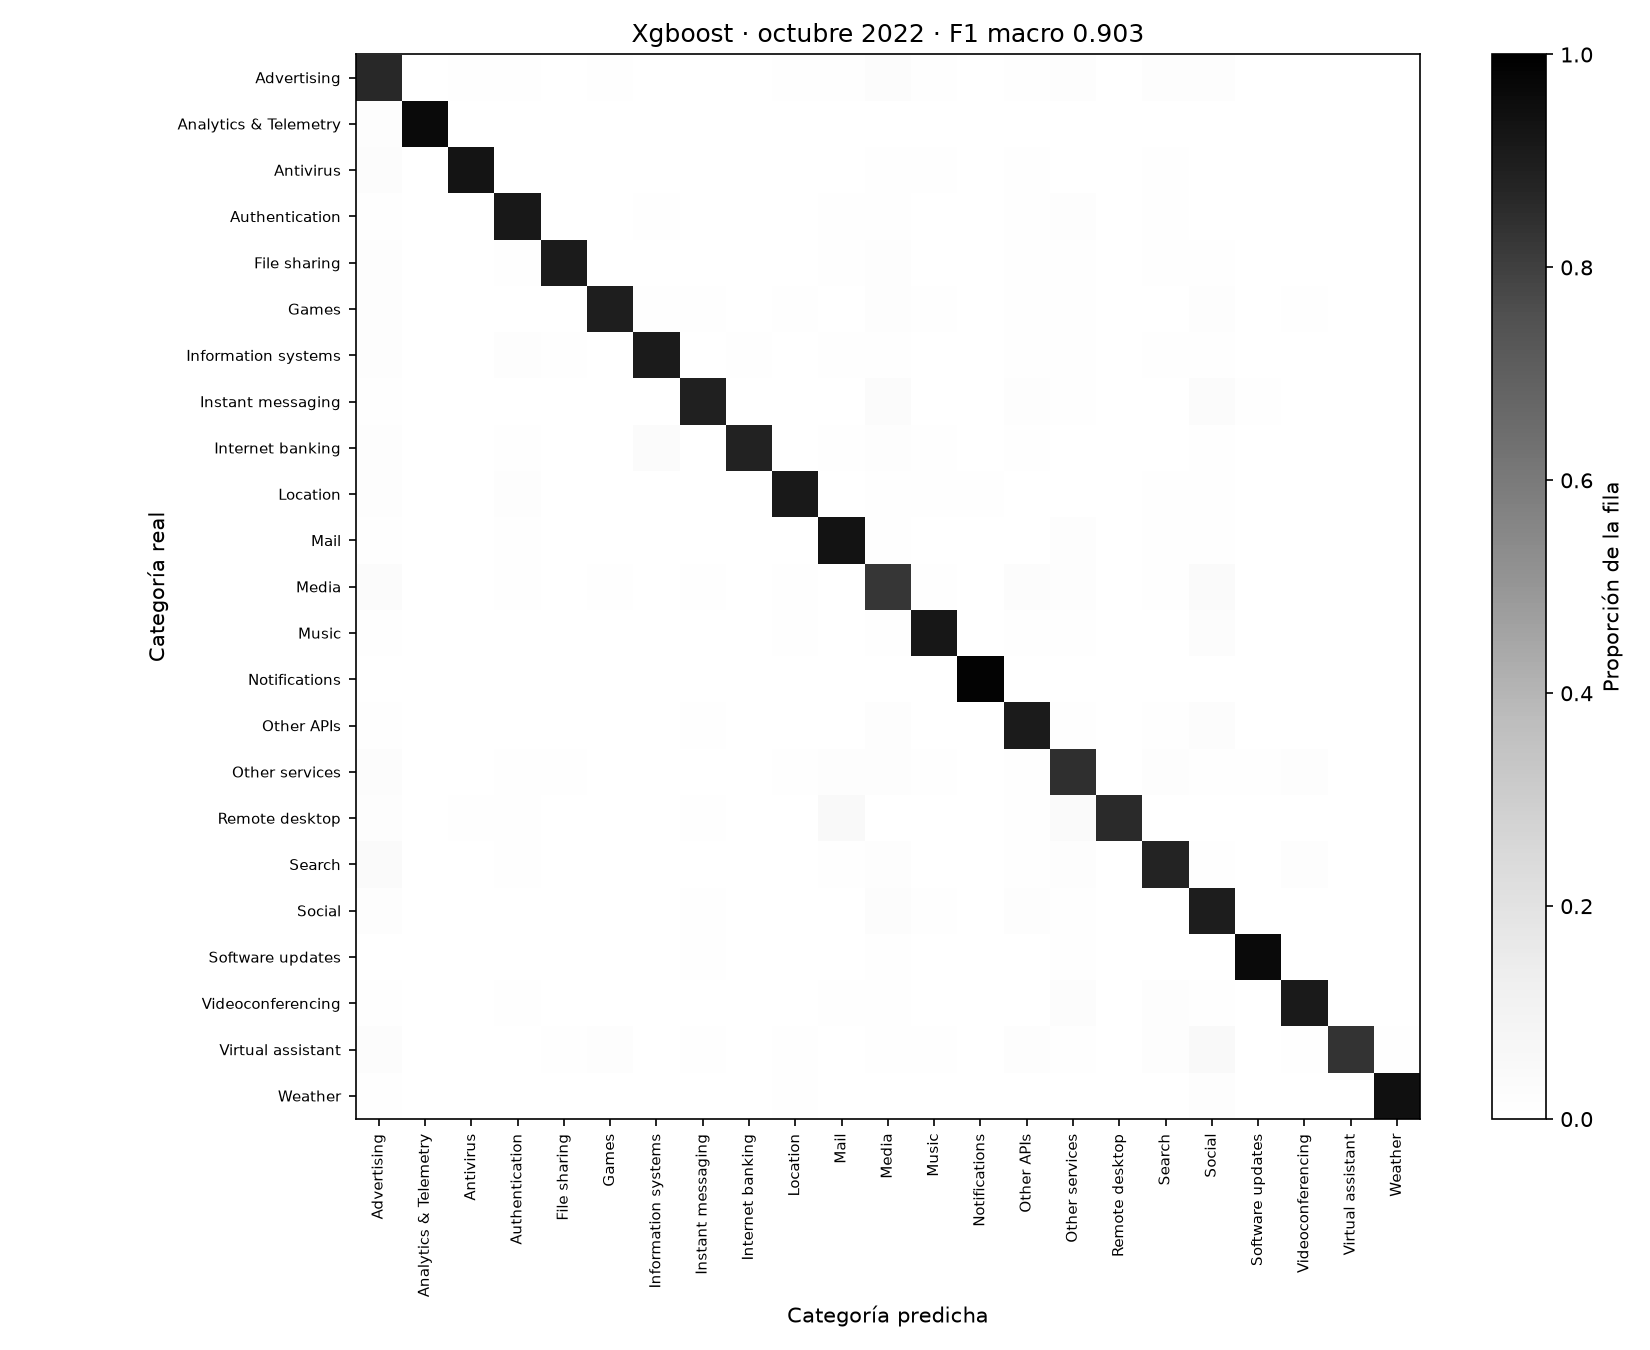

In [9]:
figura(RES / "modelos" / "xgboost" / "matriz_confusion.png", ancho=750)

## 7. Decisión

XGBoost es el modelo recomendado: es el más preciso, el que mejor resiste la deriva y clasifica cada flujo en una
fracción de milisegundo. La semana 5 encontró una configuración todavía mejor (0,911 de F1 macro, ver el notebook 04),
pero ese modelo pesa 154 MB y GitHub no admite archivos de más de 100 MB. Por eso el modelo publicado en
`models/best_model.pkl` y en la aplicación es la versión 2, y el optimizado se distribuye como archivo adjunto de una
publicación del repositorio.

## Conclusiones

1. Los cuatro modelos superan con holgura al clasificador al azar.
2. XGBoost es el mejor, con diferencias estadísticamente significativas frente a los demás.
3. El reentrenamiento basado en el diagnóstico mejoró a los cuatro modelos.
4. Las categorías que comparten infraestructura son las más difíciles de distinguir.